# TP3 — Vision par Ordinateur


In [1]:
import subprocess, sys

# Installation step-by-step (evite le CloseEvent WebSocket de Colab)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'cmake'], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dlib'], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'face_recognition'], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'ultralytics', 'opencv-python-headless',
                'numpy', 'matplotlib', 'pandas', 'Pillow', 'scipy'], check=True)
print('Installation terminee !')

Installation terminee !


In [2]:
import os, urllib.request, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt

os.makedirs('images', exist_ok=True)
os.makedirs('outputs', exist_ok=True)
os.makedirs('presence_db', exist_ok=True)

ressources = {
    'images/lena.jpg'    : 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg',
    'images/fruits.jpg'  : 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/fruits.jpg',
    'images/bus.jpg'     : 'https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/assets/bus.jpg',
    'images/zidane.jpg'  : 'https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/assets/zidane.jpg',
    'images/obama1.jpg'  : 'https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/obama.jpg',
    'images/obama2.jpg'  : 'https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/obama2.jpg',
    'images/biden.jpg'   : 'https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/biden.jpg',
}

headers = {'User-Agent': 'Mozilla/5.0'}
for path, url in ressources.items():
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers=headers)
        with urllib.request.urlopen(req, timeout=20) as r, open(path, 'wb') as f:
            f.write(r.read())
        print(f'Telechargé: {path}')

import shutil
if os.path.exists('images/obama1.jpg'):
    shutil.copy('images/obama1.jpg', 'presence_db/Obama.jpg')
    shutil.copy('images/biden.jpg',  'presence_db/Biden.jpg')

W, H = 640, 480
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter('images/sample_video.mp4', fourcc, 25, (W, H))
for i in range(120):
    frame = np.full((H, W, 3), (20, 30, 50), dtype=np.uint8)
    cx = int(60 + (W - 120) * (i / 120))
    cy = int(H//2 + 100 * np.sin(i * 0.15))
    cv2.circle(frame, (cx, cy), 30, (0, 200, 255), -1)
    cx2 = int(W - 60 - (W - 120) * (i / 120) * 0.6)
    cv2.circle(frame, (cx2, H//3), 25, (255, 100, 0), -1)
    cv2.line(frame, (W//2, 0), (W//2, H), (0, 0, 220), 2)
    out.write(frame)
out.release()

print('Environnement pret !')

Telechargé: images/lena.jpg
Telechargé: images/fruits.jpg
Telechargé: images/bus.jpg
Telechargé: images/zidane.jpg
Telechargé: images/obama1.jpg
Telechargé: images/obama2.jpg
Telechargé: images/biden.jpg
Environnement pret !


## Partie I — Concepts de base OpenCV

Dimensions: 512x512, Canaux: 3, dtype: uint8


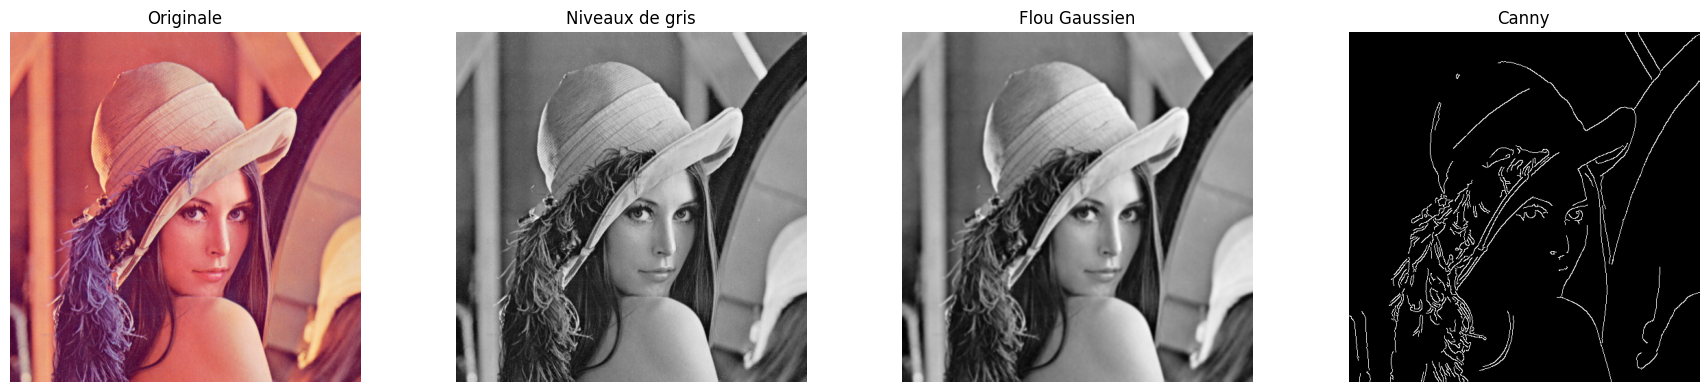

True

In [3]:
img = cv2.imread('images/lena.jpg')
h, w, c = img.shape
print(f'Dimensions: {h}x{w}, Canaux: {c}, dtype: {img.dtype}')

gray  = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur  = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blur, 100, 200)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, im, titre in zip(axes,
    [cv2.cvtColor(img, cv2.COLOR_BGR2RGB), gray, blur, edges],
    ['Originale', 'Niveaux de gris', 'Flou Gaussien', 'Canny']):
    ax.imshow(im, cmap='gray' if len(im.shape)==2 else None)
    ax.set_title(titre); ax.axis('off')
plt.tight_layout(); plt.show()

cv2.imwrite('outputs/exo1_gray.jpg', gray)
cv2.imwrite('outputs/exo1_edges.jpg', edges)

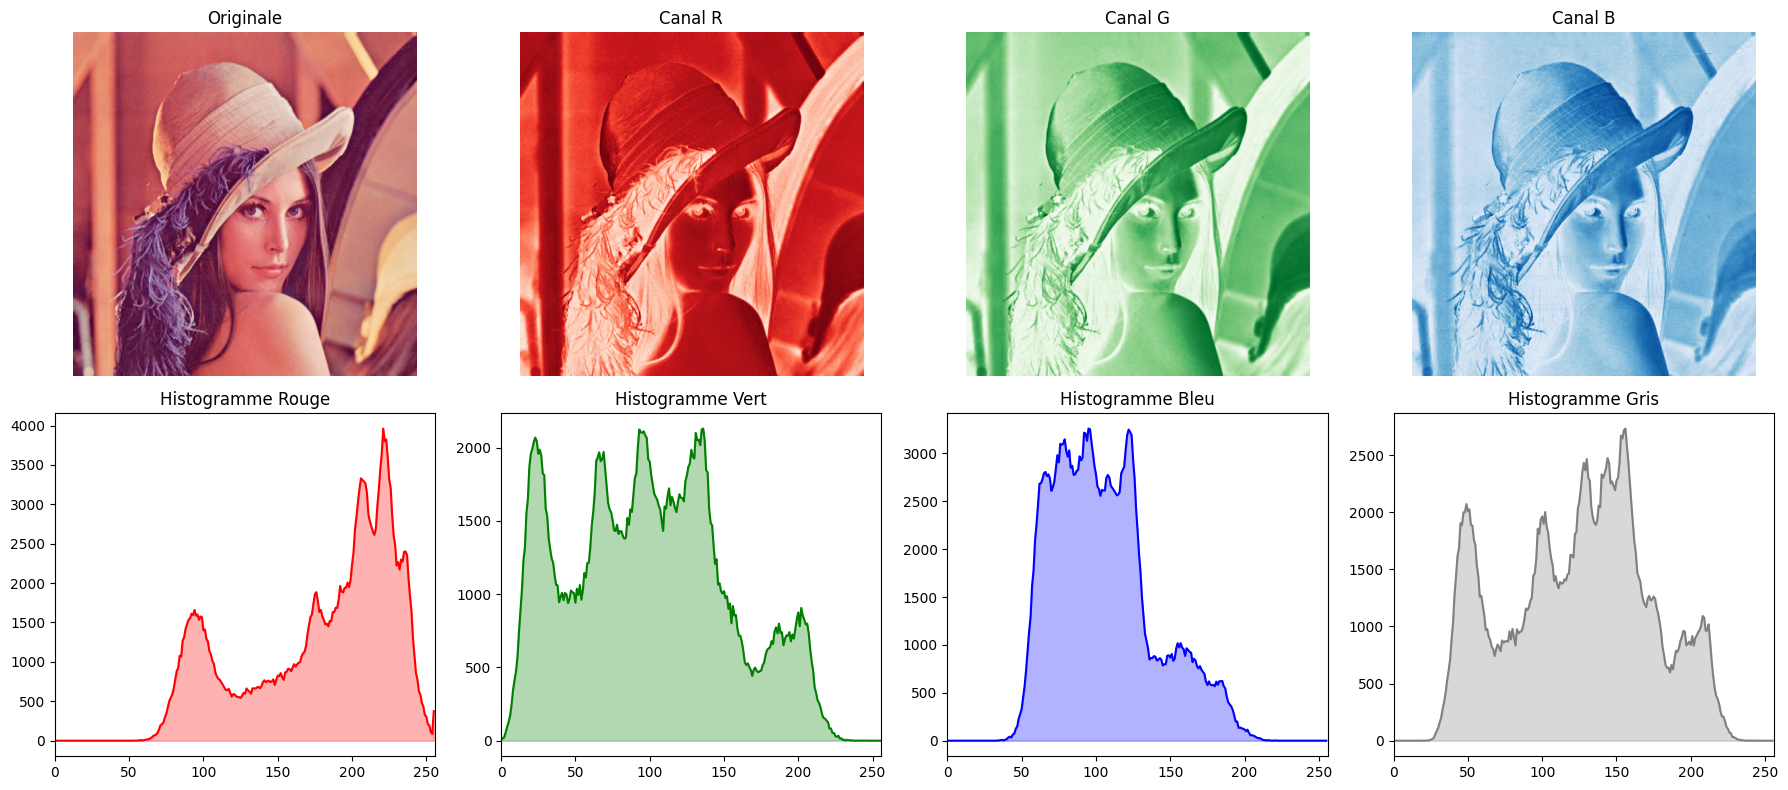

In [4]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
R, G, B = img_rgb[:,:,0], img_rgb[:,:,1], img_rgb[:,:,2]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes[0,0].imshow(img_rgb);        axes[0,0].set_title('Originale');   axes[0,0].axis('off')
axes[0,1].imshow(R, cmap='Reds'); axes[0,1].set_title('Canal R');     axes[0,1].axis('off')
axes[0,2].imshow(G, cmap='Greens'); axes[0,2].set_title('Canal G');   axes[0,2].axis('off')
axes[0,3].imshow(B, cmap='Blues'); axes[0,3].set_title('Canal B');    axes[0,3].axis('off')

for ax, (canal, couleur, nom) in zip(axes[1], [(R,'red','Rouge'),(G,'green','Vert'),(B,'blue','Bleu'),(gray,'gray','Gris')]):
    hist = cv2.calcHist([canal], [0], None, [256], [0, 256])
    ax.plot(hist, color=couleur)
    ax.fill_between(range(256), hist.flatten(), alpha=0.3, color=couleur)
    ax.set_title(f'Histogramme {nom}'); ax.set_xlim([0,256])

plt.tight_layout(); plt.show()

## Partie II — Traitements d'images

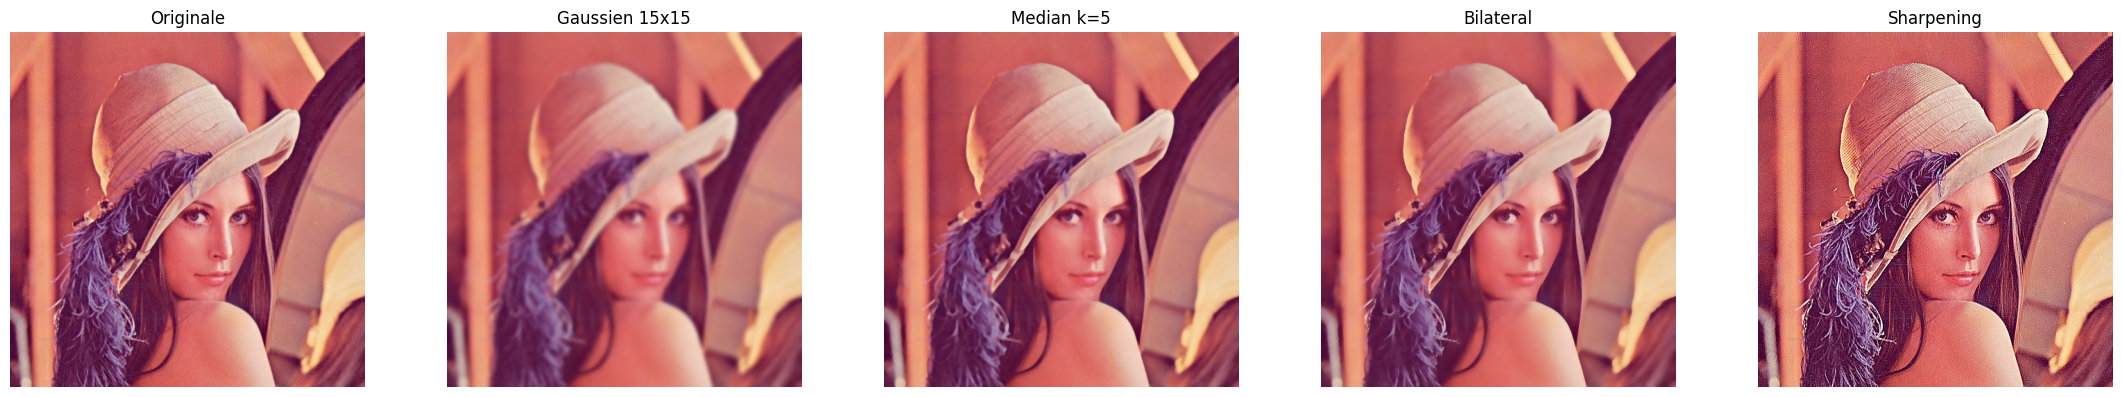

In [5]:
gauss   = cv2.GaussianBlur(img, (15, 15), 0)
median  = cv2.medianBlur(img, 5)
bilat   = cv2.bilateralFilter(img, 9, 75, 75)
kernel  = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], dtype=np.float32)
sharp   = cv2.filter2D(img, -1, kernel)

titres = ['Originale', 'Gaussien 15x15', 'Median k=5', 'Bilateral', 'Sharpening']
images = [img, gauss, median, bilat, sharp]

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, im, t in zip(axes, images, titres):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

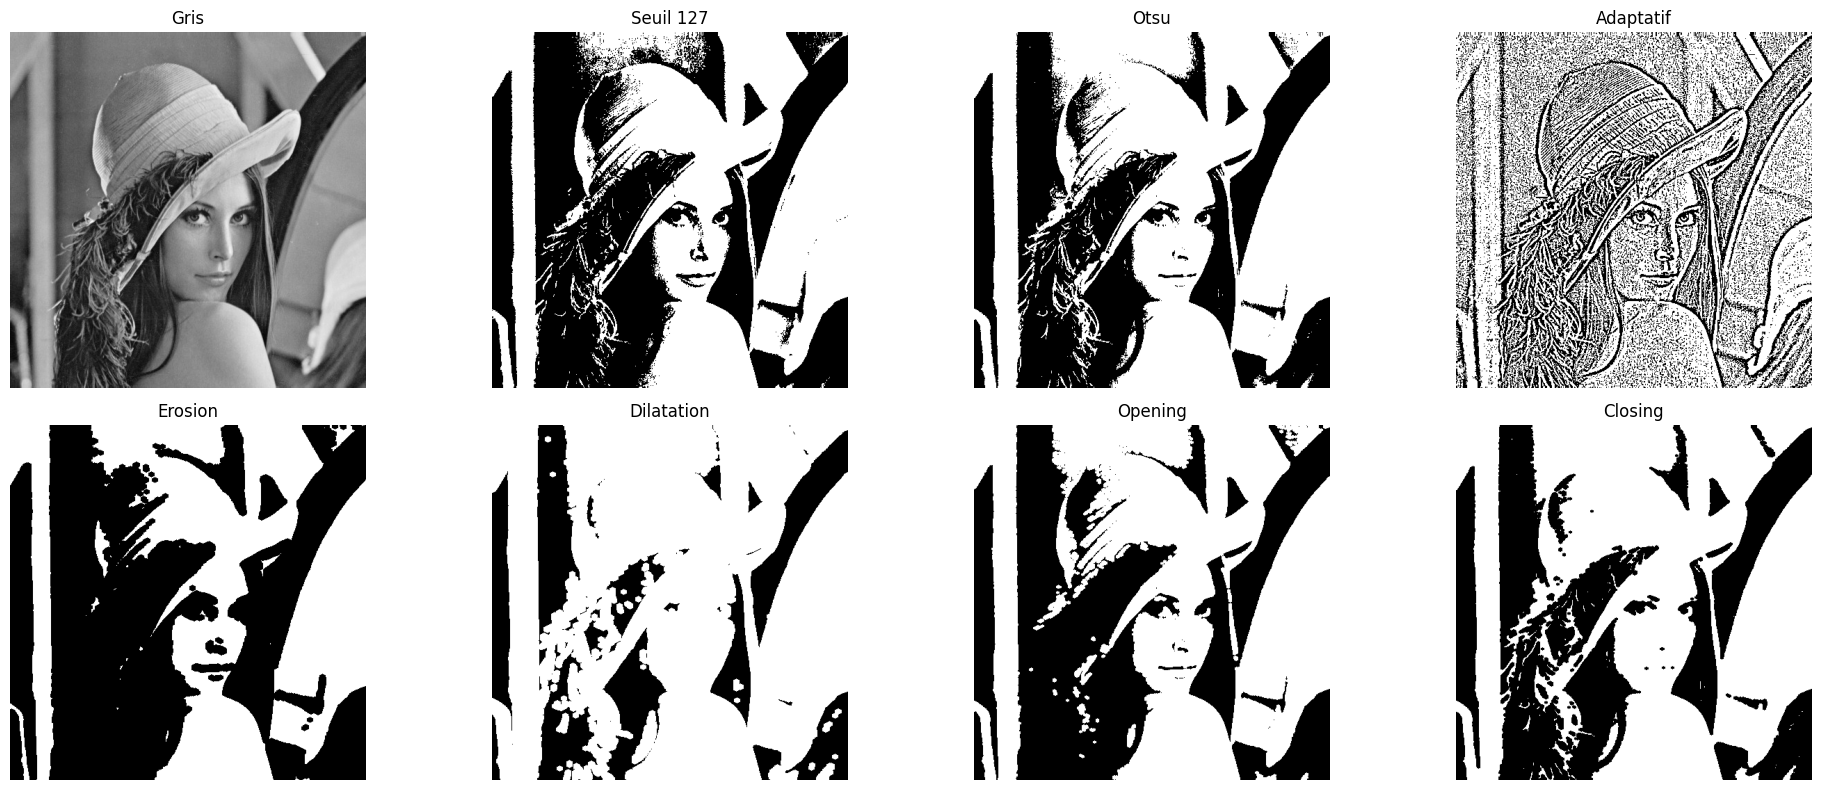

In [6]:
_, thresh_simple = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
thresh_otsu      = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
thresh_adapt     = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)

kernel3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
erode   = cv2.erode(thresh_otsu, kernel3, iterations=2)
dilate  = cv2.dilate(thresh_otsu, kernel3, iterations=2)
opening = cv2.morphologyEx(thresh_otsu, cv2.MORPH_OPEN, kernel3)
closing = cv2.morphologyEx(thresh_otsu, cv2.MORPH_CLOSE, kernel3)

titres = ['Gris','Seuil 127','Otsu','Adaptatif','Erosion','Dilatation','Opening','Closing']
images = [gray, thresh_simple, thresh_otsu, thresh_adapt, erode, dilate, opening, closing]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, im, t in zip(axes.flatten(), images, titres):
    ax.imshow(im, cmap='gray'); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

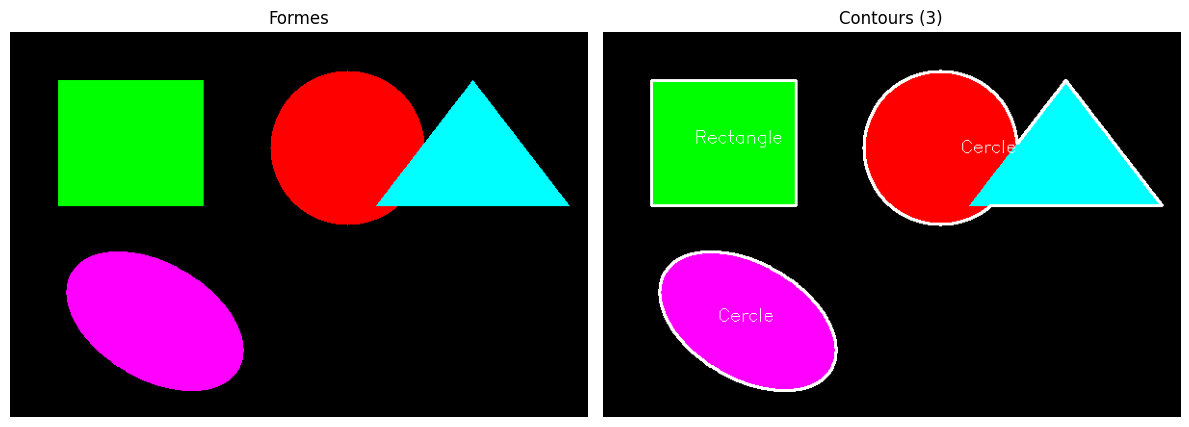

In [7]:
canvas = np.zeros((400, 600, 3), dtype=np.uint8)
cv2.rectangle(canvas, (50, 50), (200, 180), (0, 255, 0), -1)
cv2.circle(canvas, (350, 120), 80, (0, 0, 255), -1)
cv2.fillPoly(canvas, [np.array([[480,50],[580,180],[380,180]])], (255, 255, 0))
cv2.ellipse(canvas, (150, 300), (100, 60), 30, 0, 360, (255, 0, 255), -1)

gray_c = cv2.cvtColor(canvas, cv2.COLOR_BGR2GRAY)
contours, _ = cv2.findContours(gray_c, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

canvas_ann = canvas.copy()
for cnt in contours:
    approx = cv2.approxPolyDP(cnt, 0.03 * cv2.arcLength(cnt, True), True)
    n = len(approx)
    forme = 'Triangle' if n==3 else 'Rectangle' if n==4 else 'Cercle'
    M = cv2.moments(cnt)
    if M['m00']:
        cx2, cy2 = int(M['m10']/M['m00']), int(M['m01']/M['m00'])
        cv2.drawContours(canvas_ann, [cnt], -1, (255,255,255), 2)
        cv2.putText(canvas_ann, forme, (cx2-30, cy2), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,255), 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)); axes[0].set_title('Formes'); axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(canvas_ann, cv2.COLOR_BGR2RGB)); axes[1].set_title(f'Contours ({len(contours)})'); axes[1].axis('off')
plt.tight_layout(); plt.show()

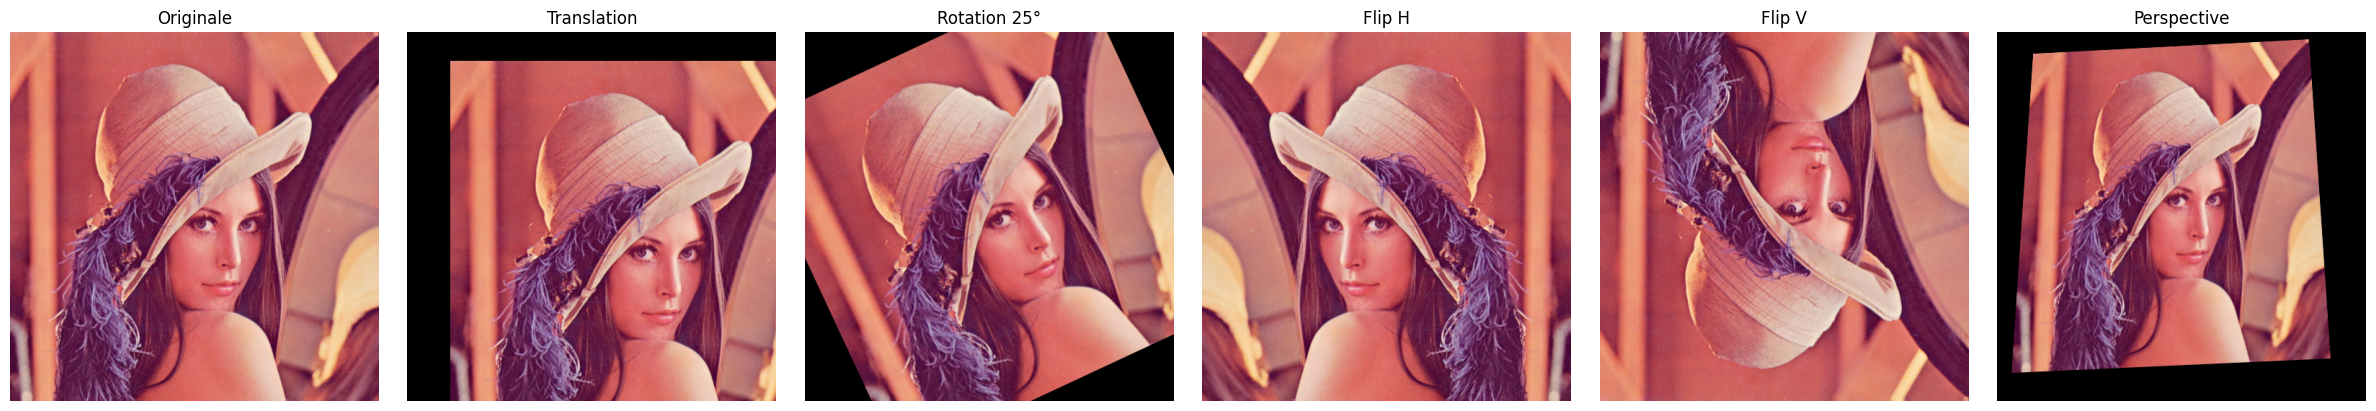

In [8]:
h, w = img.shape[:2]
M_trans = np.float32([[1,0,60],[0,1,40]])
M_rot   = cv2.getRotationMatrix2D((w//2, h//2), 25, 1.0)

translated  = cv2.warpAffine(img, M_trans, (w, h))
rotated     = cv2.warpAffine(img, M_rot,   (w, h))
flip_h      = cv2.flip(img, 1)
flip_v      = cv2.flip(img, 0)
resized     = cv2.resize(img, (w//2, h//2))
pts_src = np.float32([[0,0],[w-1,0],[0,h-1],[w-1,h-1]])
pts_dst = np.float32([[50,30],[w-80,10],[20,h-40],[w-50,h-60]])
M_p     = cv2.getPerspectiveTransform(pts_src, pts_dst)
persp   = cv2.warpPerspective(img, M_p, (w, h))

titres = ['Originale','Translation','Rotation 25°','Flip H','Flip V','Perspective']
images = [img, translated, rotated, flip_h, flip_v, persp]

fig, axes = plt.subplots(1, 6, figsize=(24, 4))
for ax, im, t in zip(axes, images, titres):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

## Partie III — Détection de visages

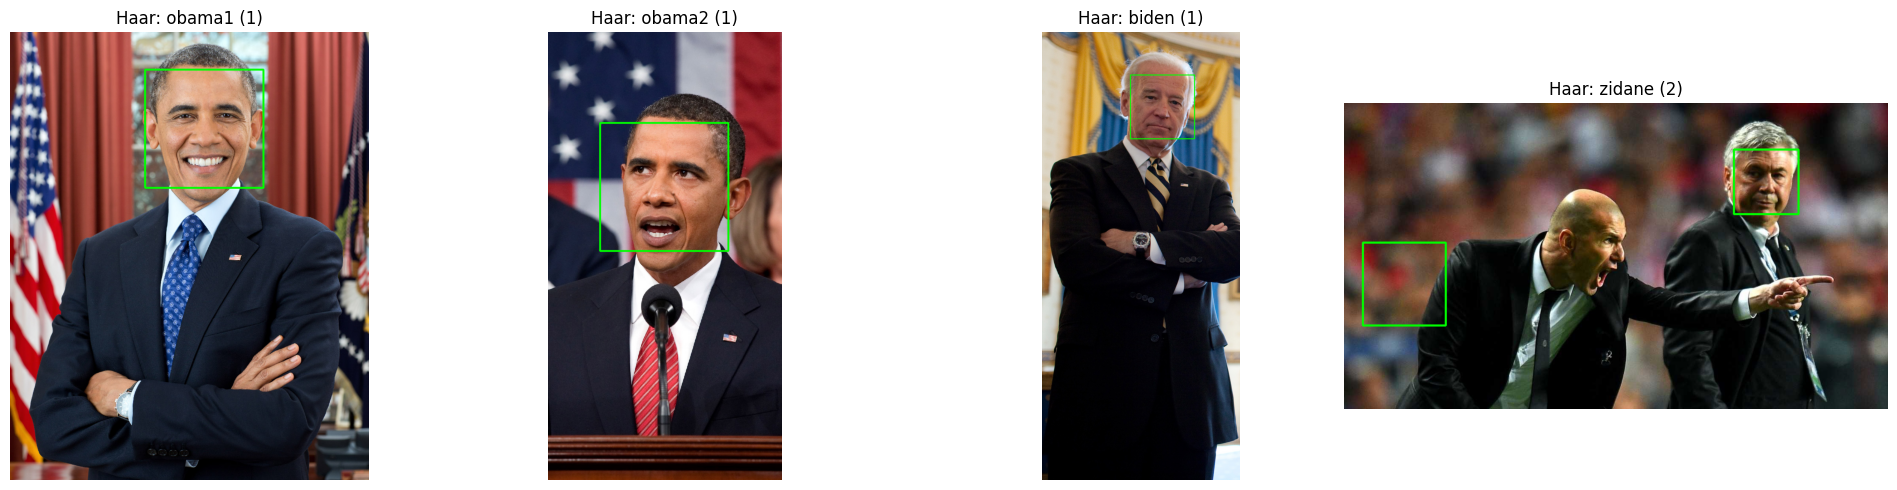

In [9]:
HAAR_PATH = 'haarcascade_frontalface_default.xml'
if not os.path.exists(HAAR_PATH):
    url = 'https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml'
    urllib.request.urlretrieve(url, HAAR_PATH)

face_cascade = cv2.CascadeClassifier(HAAR_PATH)

resultats = {}
for chemin in ['images/obama1.jpg','images/obama2.jpg','images/biden.jpg','images/zidane.jpg']:
    img_local = cv2.imread(chemin)
    if img_local is None: continue
    gray_local = cv2.cvtColor(img_local, cv2.COLOR_BGR2GRAY)
    visages = face_cascade.detectMultiScale(gray_local, 1.1, 5, minSize=(30,30))
    result = img_local.copy()
    for (x, y, w2, h2) in visages:
        cv2.rectangle(result, (x,y), (x+w2,y+h2), (0,255,0), 3)
    nom = os.path.basename(chemin).replace('.jpg','')
    resultats[f'{nom} ({len(visages)})'] = result

n = len(resultats)
fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
if n==1: axes=[axes]
for ax, (titre, im) in zip(axes, resultats.items()):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(f'Haar: {titre}'); ax.axis('off')
plt.tight_layout(); plt.show()

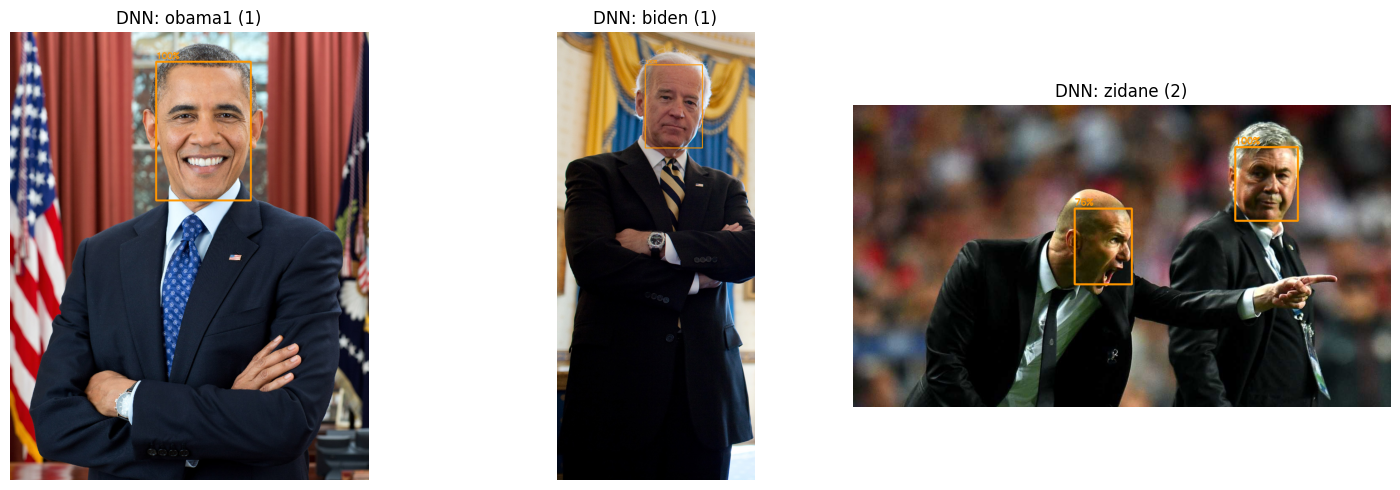

In [10]:
PROTO   = 'deploy.prototxt.txt'
WEIGHTS = 'res10_300x300_ssd_iter_140000.caffemodel'

if not os.path.exists(PROTO):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/opencv/opencv/master/samples/dnn/face_detector/deploy.prototxt', PROTO)
if not os.path.exists(WEIGHTS):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/opencv/opencv_3rdparty/dnn_samples_face_detector_20170830/' + WEIGHTS, WEIGHTS)

net = cv2.dnn.readNetFromCaffe(PROTO, WEIGHTS)

resultats_dnn = {}
for chemin in ['images/obama1.jpg','images/biden.jpg','images/zidane.jpg']:
    img_local = cv2.imread(chemin)
    if img_local is None: continue
    H2, W2 = img_local.shape[:2]
    blob = cv2.dnn.blobFromImage(cv2.resize(img_local,(300,300)), 1.0, (300,300), (104,177,123))
    net.setInput(blob)
    dets = net.forward()
    result = img_local.copy()
    n_det = 0
    for i in range(dets.shape[2]):
        conf = dets[0,0,i,2]
        if conf > 0.5:
            box = dets[0,0,i,3:7] * np.array([W2,H2,W2,H2])
            x1,y1,x2,y2 = box.astype('int')
            cv2.rectangle(result, (x1,y1),(x2,y2),(0,150,255),3)
            cv2.putText(result, f'{conf*100:.0f}%', (x1,y1-8), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,150,255), 2)
            n_det += 1
    nom = os.path.basename(chemin).replace('.jpg','')
    resultats_dnn[f'DNN: {nom} ({n_det})'] = result

n = len(resultats_dnn)
fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
if n==1: axes=[axes]
for ax, (titre, im) in zip(axes, resultats_dnn.items()):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(titre); ax.axis('off')
plt.tight_layout(); plt.show()

## Mini-Projet 1 — Système de présence par reconnaissance faciale

/usr/local/lib/python3.13/dist-packages/face_recognition_models/__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


Encodé: Biden
Encodé: Obama
  Nom       Date    Heure  Statut
Obama 2026-11-07 19:33:03 Present
Biden 2026-11-07 19:33:03  Absent


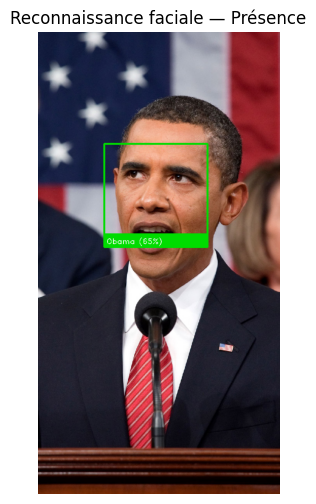

In [11]:
import face_recognition
import pandas as pd
from datetime import datetime

encodages_ref, noms_ref = [], []
for chemin in sorted(glob.glob('presence_db/*.jpg')):
    nom = os.path.splitext(os.path.basename(chemin))[0]
    img_ref = face_recognition.load_image_file(chemin)
    encs = face_recognition.face_encodings(img_ref)
    if encs:
        encodages_ref.append(encs[0])
        noms_ref.append(nom)
        print(f'Encodé: {nom}')

def reconnaitre(chemin_img, seuil=0.55):
    img_test = face_recognition.load_image_file(chemin_img)
    img_cv   = cv2.imread(chemin_img)
    lieux    = face_recognition.face_locations(img_test, model='hog')
    encs     = face_recognition.face_encodings(img_test, lieux)
    presents = []
    result   = img_cv.copy()
    for (top,right,bottom,left), enc in zip(lieux, encs):
        distances = face_recognition.face_distance(encodages_ref, enc)
        idx = np.argmin(distances) if len(distances) else -1
        if idx >= 0 and distances[idx] < seuil:
            nom_r  = noms_ref[idx]
            conf   = (1 - distances[idx]) * 100
            label  = f'{nom_r} ({conf:.0f}%)'
            color  = (0, 220, 0)
            presents.append(nom_r)
        else:
            label = 'Inconnu'
            color = (0, 0, 220)
        cv2.rectangle(result, (left,top),(right,bottom), color, 3)
        cv2.rectangle(result, (left,bottom-35),(right,bottom), color, cv2.FILLED)
        cv2.putText(result, label, (left+6,bottom-8), cv2.FONT_HERSHEY_DUPLEX, 0.65, (255,255,255), 1)
    return result, presents

img_res, presents = reconnaitre('images/obama2.jpg')

date_str  = datetime.now().strftime('%Y-%m-%d')
heure_str = datetime.now().strftime('%H:%M:%S')
donnees   = [{'Nom':n,'Date':date_str,'Heure':heure_str,'Statut':'Present'} for n in presents]
for n in noms_ref:
    if n not in presents:
        donnees.append({'Nom':n,'Date':date_str,'Heure':heure_str,'Statut':'Absent'})

df = pd.DataFrame(donnees)
df.to_csv(f'presence_{date_str}.csv', index=False)
print(df.to_string(index=False))

plt.figure(figsize=(7,6))
plt.imshow(cv2.cvtColor(img_res, cv2.COLOR_BGR2RGB))
plt.title('Reconnaissance faciale — Présence')
plt.axis('off'); plt.show()

## Mini-Projet 2 — Détecteur de somnolence (EAR)

In [12]:
import bz2, shutil
MODEL_68 = 'shape_predictor_68_face_landmarks.dat'
if not os.path.exists(MODEL_68):
    url = 'http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2'
    print('Telechargement du modele 68 landmarks (~100 Mo)...')
    urllib.request.urlretrieve(url, MODEL_68 + '.bz2')
    with bz2.BZ2File(MODEL_68 + '.bz2') as fr, open(MODEL_68, 'wb') as fw:
        shutil.copyfileobj(fr, fw)
    os.remove(MODEL_68 + '.bz2')
print('Modele pret.')

Telechargement du modele 68 landmarks (~100 Mo)...
Modele pret.


EAR = 0.2259 -> SOMNOLENCE!


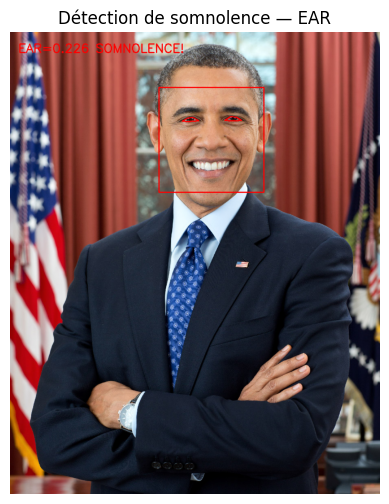

In [13]:
import dlib
from scipy.spatial import distance as dist

EAR_SEUIL = 0.25

def ear(oeil):
    A = dist.euclidean(oeil[1], oeil[5])
    B = dist.euclidean(oeil[2], oeil[4])
    C = dist.euclidean(oeil[0], oeil[3])
    return (A + B) / (2.0 * C)

detecteur = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor(MODEL_68)

def analyser(chemin_img):
    img_rgb = face_recognition.load_image_file(chemin_img)
    img_ann = cv2.imread(chemin_img).copy()
    gris    = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    visages = detecteur(gris, 0)
    for face in visages:
        shape  = predictor(gris, face)
        oeil_g = np.array([(shape.part(i).x, shape.part(i).y) for i in range(42,48)])
        oeil_d = np.array([(shape.part(i).x, shape.part(i).y) for i in range(36,42)])
        ear_moy = (ear(oeil_g) + ear(oeil_d)) / 2.0
        couleur = (0,0,255) if ear_moy < EAR_SEUIL else (0,255,0)
        statut  = 'SOMNOLENCE!' if ear_moy < EAR_SEUIL else 'Eveille'
        cv2.drawContours(img_ann, [cv2.convexHull(oeil_g)], -1, couleur, 2)
        cv2.drawContours(img_ann, [cv2.convexHull(oeil_d)], -1, couleur, 2)
        x1,y1,x2,y2 = face.left(),face.top(),face.right(),face.bottom()
        cv2.rectangle(img_ann,(x1,y1),(x2,y2),couleur,2)
        cv2.putText(img_ann, f'EAR={ear_moy:.3f} {statut}', (20,50), cv2.FONT_HERSHEY_SIMPLEX, 1.0, couleur, 2)
        print(f'EAR = {ear_moy:.4f} -> {statut}')
    return img_ann

result = analyser('images/obama1.jpg')
cv2.imwrite('outputs/mp2_somnolence.jpg', result)
plt.figure(figsize=(7,6))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('Détection de somnolence — EAR'); plt.axis('off'); plt.show()

## Mini-Projet 3 — Compteur de personnes avec YOLO v8 + Ligne Virtuelle

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Entrees=0  Sorties=0  Presents=0


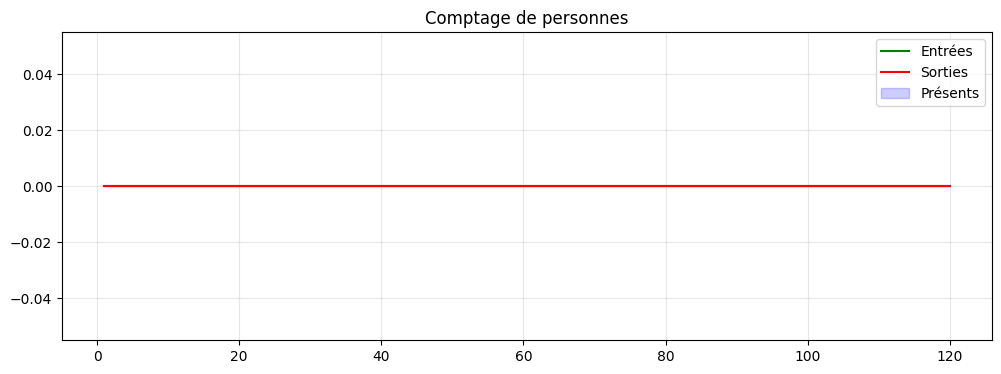

In [14]:
from ultralytics import YOLO
import pandas as pd

model_yolo = YOLO('yolov8n.pt')

VIDEO_IN  = 'images/sample_video.mp4'
VIDEO_OUT = 'outputs/mp3_compteur.mp4'

cap    = cv2.VideoCapture(VIDEO_IN)
fps_v  = cap.get(cv2.CAP_PROP_FPS)
W_v    = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H_v    = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
LIGNE  = W_v // 2

fourcc_out = cv2.VideoWriter_fourcc(*'mp4v')
out_v = cv2.VideoWriter(VIDEO_OUT, fourcc_out, fps_v, (W_v, H_v))

objets_prev = {}
id_cpt = 0
ENTREE = 0
SORTIE = 0
historique = []

fi = 0
while True:
    ret, frame = cap.read()
    if not ret: break
    fi += 1
    results = model_yolo(frame, classes=[0], conf=0.35, iou=0.45, verbose=False)[0]
    objets = {}
    for box in results.boxes:
        x1,y1,x2,y2 = map(int, box.xyxy[0].tolist())
        cx, cy = (x1+x2)//2, (y1+y2)//2
        meilleur_id, meilleure_dist = None, 80
        for oid,(ocx,ocy) in objets_prev.items():
            d = np.sqrt((cx-ocx)**2+(cy-ocy)**2)
            if d < meilleure_dist:
                meilleure_dist = d; meilleur_id = oid
        if meilleur_id is None:
            meilleur_id = id_cpt; id_cpt += 1
        if meilleur_id in objets_prev:
            cx_prev = objets_prev[meilleur_id][0]
            if cx_prev < LIGNE <= cx: ENTREE += 1
            elif cx_prev > LIGNE >= cx: SORTIE += 1
        objets[meilleur_id] = (cx, cy)
        cv2.rectangle(frame,(x1,y1),(x2,y2),(0,220,0),2)
        cv2.circle(frame,(cx,cy),4,(0,0,255),-1)
    objets_prev = objets
    cv2.line(frame,(LIGNE,0),(LIGNE,H_v),(0,0,220),2)
    cv2.putText(frame,f'ENTREE:{ENTREE}',(LIGNE+10,40),cv2.FONT_HERSHEY_SIMPLEX,0.9,(0,220,0),2)
    cv2.putText(frame,f'SORTIE:{SORTIE}',(LIGNE+10,80),cv2.FONT_HERSHEY_SIMPLEX,0.9,(0,0,220),2)
    cv2.putText(frame,f'PRESENT:{ENTREE-SORTIE}',(20,H_v-20),cv2.FONT_HERSHEY_SIMPLEX,1,(255,255,0),2)
    historique.append({'frame':fi,'entree':ENTREE,'sortie':SORTIE,'present':ENTREE-SORTIE})
    out_v.write(frame)

cap.release(); out_v.release()
print(f'Entrees={ENTREE}  Sorties={SORTIE}  Presents={ENTREE-SORTIE}')

df_h = pd.DataFrame(historique)
df_h.to_csv('outputs/mp3_comptage.csv', index=False)

plt.figure(figsize=(12,4))
plt.plot(df_h['frame'], df_h['entree'], label='Entrées', color='green')
plt.plot(df_h['frame'], df_h['sortie'], label='Sorties', color='red')
plt.fill_between(df_h['frame'], df_h['present'], alpha=0.2, label='Présents', color='blue')
plt.title('Comptage de personnes'); plt.legend(); plt.grid(alpha=0.3)
plt.savefig('outputs/mp3_graphique.png', dpi=150); plt.show()

## Mini-Projet 4 — Floutage automatique des visages (RGPD)

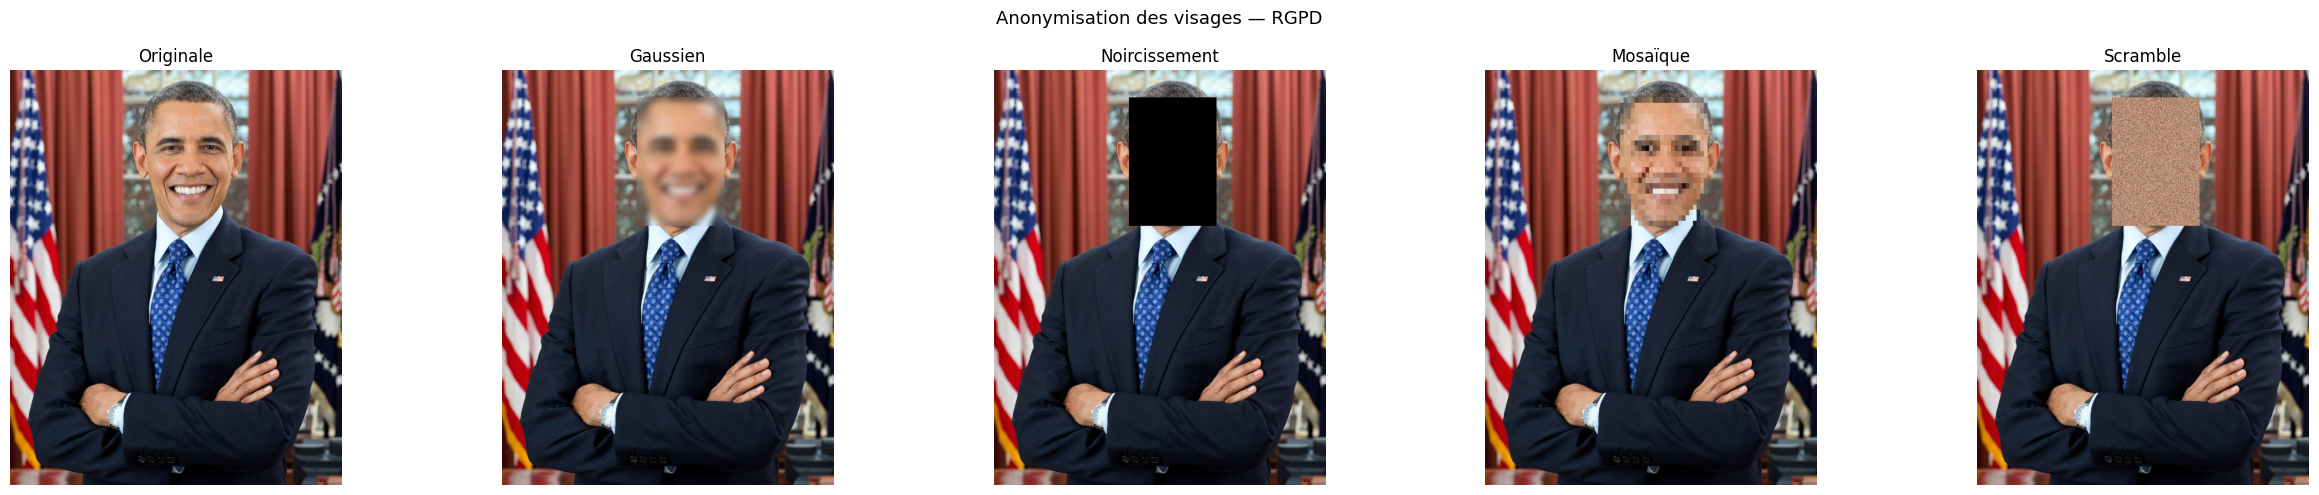

Images anonymisées sauvegardées.


In [15]:
def flouter(img, x1, y1, x2, y2, methode='gauss'):
    roi = img[y1:y2, x1:x2]
    if roi.size == 0: return img
    if methode == 'gauss':
        roi_f = cv2.GaussianBlur(roi, (51,51), 0)
    elif methode == 'noir':
        roi_f = np.zeros_like(roi)
    elif methode == 'mosaique':
        f = max(1, min(roi.shape[1], roi.shape[0]) // 10)
        small = cv2.resize(roi,(f,f), interpolation=cv2.INTER_LINEAR)
        roi_f = cv2.resize(small,(roi.shape[1],roi.shape[0]), interpolation=cv2.INTER_NEAREST)
    elif methode == 'scramble':
        flat = roi.reshape(-1,roi.shape[2])
        idx  = np.random.default_rng(42).permutation(len(flat))
        roi_f = flat[idx].reshape(roi.shape)
    else:
        roi_f = roi
    result = img.copy()
    result[y1:y2, x1:x2] = roi_f
    return result

def anonymiser(chemin_img, methode='gauss'):
    img_local = cv2.imread(chemin_img)
    H2, W2 = img_local.shape[:2]
    blob = cv2.dnn.blobFromImage(cv2.resize(img_local,(300,300)),1.0,(300,300),(104,177,123))
    net.setInput(blob)
    dets = net.forward()
    result = img_local.copy()
    for i in range(dets.shape[2]):
        conf = dets[0,0,i,2]
        if conf > 0.45:
            box = dets[0,0,i,3:7] * np.array([W2,H2,W2,H2])
            x1,y1,x2,y2 = box.astype('int')
            result = flouter(result, x1,y1,x2,y2, methode)
    return result

IMG_REF = 'images/obama1.jpg'
methodes = [('gauss','Gaussien'),('noir','Noircissement'),('mosaique','Mosaïque'),('scramble','Scramble')]

imgs_anon = {'Originale': cv2.imread(IMG_REF)}
for methode, titre in methodes:
    imgs_anon[titre] = anonymiser(IMG_REF, methode)

n = len(imgs_anon)
fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
for ax, (titre, im) in zip(axes, imgs_anon.items()):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(titre); ax.axis('off')
plt.suptitle('Anonymisation des visages — RGPD', fontsize=13)
plt.tight_layout(); plt.show()

cv2.imwrite('outputs/mp4_gauss.jpg',    anonymiser(IMG_REF, 'gauss'))
cv2.imwrite('outputs/mp4_mosaique.jpg', anonymiser(IMG_REF, 'mosaique'))
print('Images anonymisées sauvegardées.')

In [16]:
cap_f   = cv2.VideoCapture('images/sample_video.mp4')
fps_f   = cap_f.get(cv2.CAP_PROP_FPS)
W_f     = int(cap_f.get(cv2.CAP_PROP_FRAME_WIDTH))
H_f     = int(cap_f.get(cv2.CAP_PROP_FRAME_HEIGHT))
out_f   = cv2.VideoWriter('outputs/mp4_video_anonymisee.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps_f, (W_f, H_f))

while True:
    ret, frame_f = cap_f.read()
    if not ret: break
    blob_f = cv2.dnn.blobFromImage(cv2.resize(frame_f,(300,300)),1.0,(300,300),(104,177,123))
    net.setInput(blob_f)
    dets_f = net.forward()
    for i in range(dets_f.shape[2]):
        if dets_f[0,0,i,2] > 0.4:
            box = dets_f[0,0,i,3:7] * np.array([W_f,H_f,W_f,H_f])
            x1,y1,x2,y2 = box.astype('int')
            frame_f = flouter(frame_f, x1,y1,x2,y2, 'mosaique')
    cv2.putText(frame_f,'ANONYMISE - RGPD',(10,H_f-15),cv2.FONT_HERSHEY_SIMPLEX,0.7,(200,200,50),2)
    out_f.write(frame_f)

cap_f.release(); out_f.release()
print('Video anonymisée sauvegardée -> outputs/mp4_video_anonymisee.mp4')

Video anonymisée sauvegardée -> outputs/mp4_video_anonymisee.mp4


## Bilan — Fichiers générés

In [17]:
for f in sorted(glob.glob('outputs/*') + glob.glob('presence_*.csv')):
    taille = os.path.getsize(f) / 1024
    print(f'  {taille:8.1f} Ko  {f}')

      64.1 Ko  outputs/exo1_edges.jpg
      86.7 Ko  outputs/exo1_gray.jpg
     301.5 Ko  outputs/mp2_somnolence.jpg
       1.1 Ko  outputs/mp3_comptage.csv
     260.9 Ko  outputs/mp3_compteur.mp4
      30.2 Ko  outputs/mp3_graphique.png
     267.5 Ko  outputs/mp4_gauss.jpg
     277.1 Ko  outputs/mp4_mosaique.jpg
     207.2 Ko  outputs/mp4_video_anonymisee.mp4
       0.1 Ko  presence_2026-11-07.csv
